# Diagnóstico objetivo3 v1 — solo datos y predicciones guardados

Notebook descriptivo, no personal. Cero nuevos fits/carga de modelos. 2021–2025 ya
vistos: exploratorio, sin confirmación independiente, causalidad o pronóstico
anticipado demostrado. Ejecutar desde raíz o subcarpeta del repositorio con entorno
exacto Python3.12.14/sklearn1.9.1/54paqueteslock. Fuente editable `01_diagnostico.py`;
generador valida nbformat y ejecuta de verdad seis celdas mediante Python exec.
Tablas completas en fase1/tablas; unidades/n/límites acompañan resultados.


In [1]:
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'diagnostico_objetivo3_v1/fase1/fuentes/comun_diagnostico.py').exists())
sys.path.insert(0, str(root / 'diagnostico_objetivo3_v1/fase1/fuentes'))
from comun_diagnostico import environment, read_json, csv, OUT, TABLES, FIGS
env = environment()
audit = read_json(OUT / 'auditoria_diagnostico.json')
preflight = read_json(OUT / 'preflight_actual.json')
assert audit['aprobado'] and env['aprobado'] and preflight['reconstruccion_exacta']
print('DIAGNÓSTICO EXPLORATORIO. Cero fits;solo guardados;sin causalidad ni confirmación independiente.')
print('Python', env['python'], 'sklearn', env['sklearn'], 'paquetes', len(env['paquetes']), env['pip_check'])
print('Panel:', preflight['filas'], 'filas;', preflight['territorios'], 'territorios;', preflight['cambios'], 'cambios')
print('Internas:', audit['internos_originales'], 'originales;', audit['internos_unicos'], 'únicas;4años únicos')
print('Externas:', audit['externas'], '=7×165;seleccionesv5intactas;modeloscargados:', audit['modelos_deserializados'])



DIAGNÓSTICO EXPLORATORIO. Cero fits;solo guardados;sin causalidad ni confirmación independiente.
Python 3.12.14 sklearn 1.9.1 paquetes 54 No broken requirements found.
Panel: 231 filas; 33 territorios; 198 cambios
Internas: 11880 originales; 4752 únicas;4años únicos
Externas: 1155 =7×165;seleccionesv5intactas;modeloscargados: 0


In [2]:
annual = csv(TABLES / 'estabilidad_anual.csv')
print(annual[['periodo', 'n', 'media', 'mediana', 'iqr', 'n_negativos', 'n_ceros', 'n_positivos']].to_string(index=False))
print('Unidades:puntos;2021 respecto2019,intervalo2,sin anualizar;restointervalo1.')
transitions = csv(TABLES / 'transiciones_signo.csv')
print(transitions.groupby(['anio_desde','anio_hasta']).cambia_signo.agg(['sum','size']).to_string())
print('Particionesoriginales completas en contrastes_particiones_originales.csv;no contar10como10años.')



              periodo   n     media   mediana      iqr  n_negativos  n_ceros  n_positivos
global_2019_2021_2025 198  0.777383  1.987191 5.760258           68        0          130
                 2019  33 -5.815757 -5.716775 2.399272           33        0            0
                 2021  33 -1.407090 -1.200614 3.888980           23        0           10
                 2022  33  4.506233  4.578600 2.151415            2        0           31
                 2023  33  2.250916  2.668274 1.437207            2        0           31
                 2024  33  3.635062  3.082523 3.050207            2        0           31
                 2025  33  1.494932  1.976252 2.704959            6        0           27
Unidades:puntos;2021 respecto2019,intervalo2,sin anualizar;restointervalo1.
                       sum  size
anio_desde anio_hasta           
2019       2021         10    33
2021       2022         23    33
2022       2023          4    33
2023       2024          4    33
2024  

In [3]:
variation = csv(TABLES / 'variacion_entradas.csv')
assoc = csv(TABLES / 'asociaciones_objetivo.csv')
pairs = csv(TABLES / 'asociaciones_entre_entradas.csv')
exact_pairs = csv(TABLES / 'redundancia_exacta.csv')
print('18entradasexactas:126resúmenes;', int(variation.constante_exacta.sum()), 'constantes;', int(variation.no_finitos.sum()), 'no finitos')
print('252asociacionesobjetivo;', len(pairs), 'entreentradas;', int(exact_pairs.iguales_exactamente.sum()), 'paresidénticos')
shown = assoc[(assoc.metodo == 'spearman') & assoc.entrada.isin(['puntaje_previo','ipm','cambio_ipm'])]
print(shown[['periodo','entrada','n','correlacion','razon']].to_string(index=False))
print('Pearson/Spearman completos en tablas;rangosmedios;sin p-valores/selección;correlación no es capacidadpredictiva.')



18entradasexactas:126resúmenes; 0 constantes; 0 no finitos
252asociacionesobjetivo; 2142 entreentradas; 0 paresidénticos
periodo        entrada   n  correlacion  razon
 global puntaje_previo 198    -0.052277    NaN
 global            ipm 198    -0.151773    NaN
 global     cambio_ipm 198    -0.063199    NaN
   2019 puntaje_previo  33     0.027406    NaN
   2019            ipm  33    -0.034094    NaN
   2019     cambio_ipm  33    -0.025407    NaN
   2021 puntaje_previo  33    -0.145722    NaN
   2021            ipm  33    -0.129534    NaN
   2021     cambio_ipm  33    -0.089245    NaN
   2022 puntaje_previo  33     0.123663    NaN
   2022            ipm  33    -0.055667    NaN
   2022     cambio_ipm  33    -0.254117    NaN
   2023 puntaje_previo  33    -0.400067    NaN
   2023            ipm  33     0.378238    NaN
   2023     cambio_ipm  33    -0.332553    NaN
   2024 puntaje_previo  33     0.218583    NaN
   2024            ipm  33     0.090271    NaN
   2024     cambio_ipm  33    -0.

In [4]:
unique_metrics = csv(TABLES / 'metricas_internas_unicas.csv')
total = unique_metrics[unique_metrics.periodo == 'total']
print(total.groupby('familia').agg(configuraciones=('id','size'), n_por_configuracion=('n','first'),
                                 mae_min_descriptivo=('mae','min'), mae_max=('mae','max'),
                                 sesgo_min=('sesgo','min'), sesgo_max=('sesgo','max')).to_string())
print(csv(TABLES / 'conteos_ventaja_interna_por_anio.csv').to_string(index=False))
external_metrics = csv(TABLES / 'metricas_externas.csv')
print(external_metrics[(external_metrics.procedimiento=='global') &
                       (~external_metrics.periodo.str.startswith('territorio'))]
      [['periodo','n','mae','rmse','sesgo','delta_mae_pareado','direccion_acertada']].to_string(index=False))
print('Mínimos internos descriptivos;no nuevosganadores;35ajustados sinexternas,no fabricadas.')
print('Direcciónexacta−/0/+;persistencia0 no acierta cambiosno0 aunque tenga menorMAE.')



                   configuraciones  n_por_configuracion  mae_min_descriptivo   mae_max  sesgo_min  sesgo_max
familia                                                                                                     
boosting_absoluto               20                  132             4.758037  5.761295  -5.285045  -4.156112
mediana                         15                  132             5.005407  5.574262  -4.972228  -4.205567
persistencia                     1                  132             3.724935  3.724935  -2.246280  -2.246280
  periodo  n_configuraciones  n_por_configuracion  superiores_persistencia
anio_2021                 35                   33                        0
anio_2022                 35                   33                        0
anio_2023                 35                   33                        0
anio_2024                 35                   33                       33
  periodo   n      mae     rmse     sesgo  delta_mae_pareado  direccion_acertada

In [5]:
hypotheses = csv(TABLES / 'matriz_hipotesis.csv')
print(hypotheses[['id','hipotesis','estado','n']].to_string(index=False))
alternatives = csv(TABLES / 'alternativas_y_pruebas_futuras.csv')
print(alternatives[['alternativa','conclusion']].to_string(index=False))
print('Matrizcompleta:ubicación/favor/contra/impacto/alternativa/resolución/pendiente. Ningúnpunto departidamejorvalidado.')
print('Nuevoexperimento:requiere protocolo/autorización separados;no grilla/hiperparámetros fijados.')
print('Guainía238vs404/21.012106puntos,evidenciahistórica;procedencia local noautenticada;IPMhogares/alumnos;colegio/residencia;enlaceecológico;dependencia/pocosaños.')



id                                                                       hipotesis                     estado                                                                              n
H1                                     La distribución del cambio varía entre años   apoyada descriptivamente                               198 cambios;33por año;6años;4validaciones únicas
H2                    Las asociaciones anuales observadas conservan signo uniforme                contradicha                  18entradas×6años×33territorios;asociaciones no independientes
H3               Entradas constantes o duplicadas exactamente explican los errores                contradicha                              126resúmenes=18×7periodos;1071pares=153×7periodos
H4                            La redundancia parcial causa el fracaso de la grilla insuficientemente evaluada              198pares para asociación;132pares por candidato;35configuraciones
H5         Los cambios predichos históricos presentan e

01_distribuciones_anuales.png
02_trayectorias_33.png
03_contrastes_particiones.png
04_asociaciones_anuales.png
05_deltas_internos.png


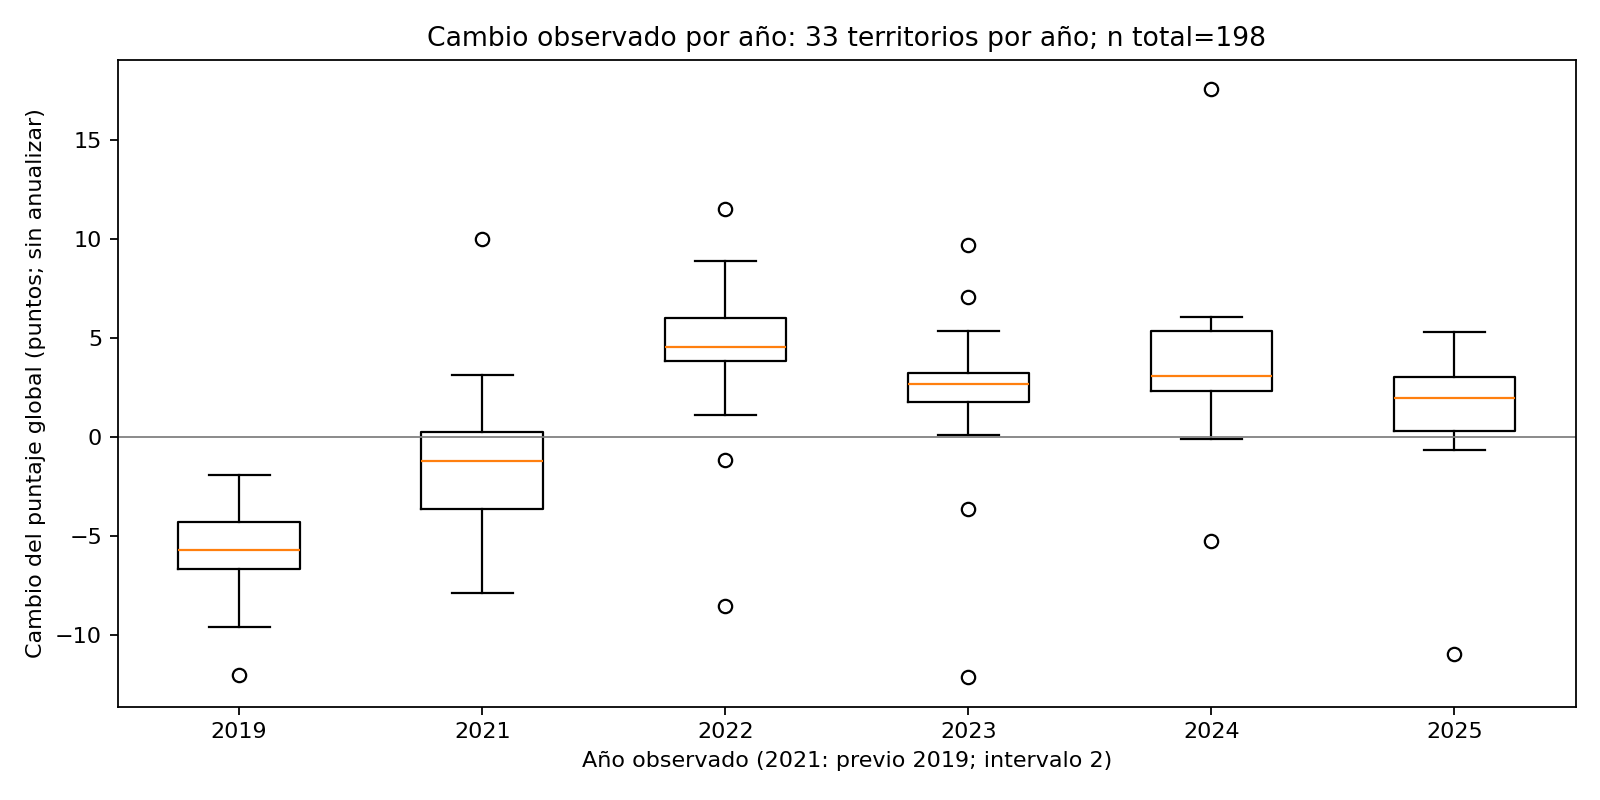

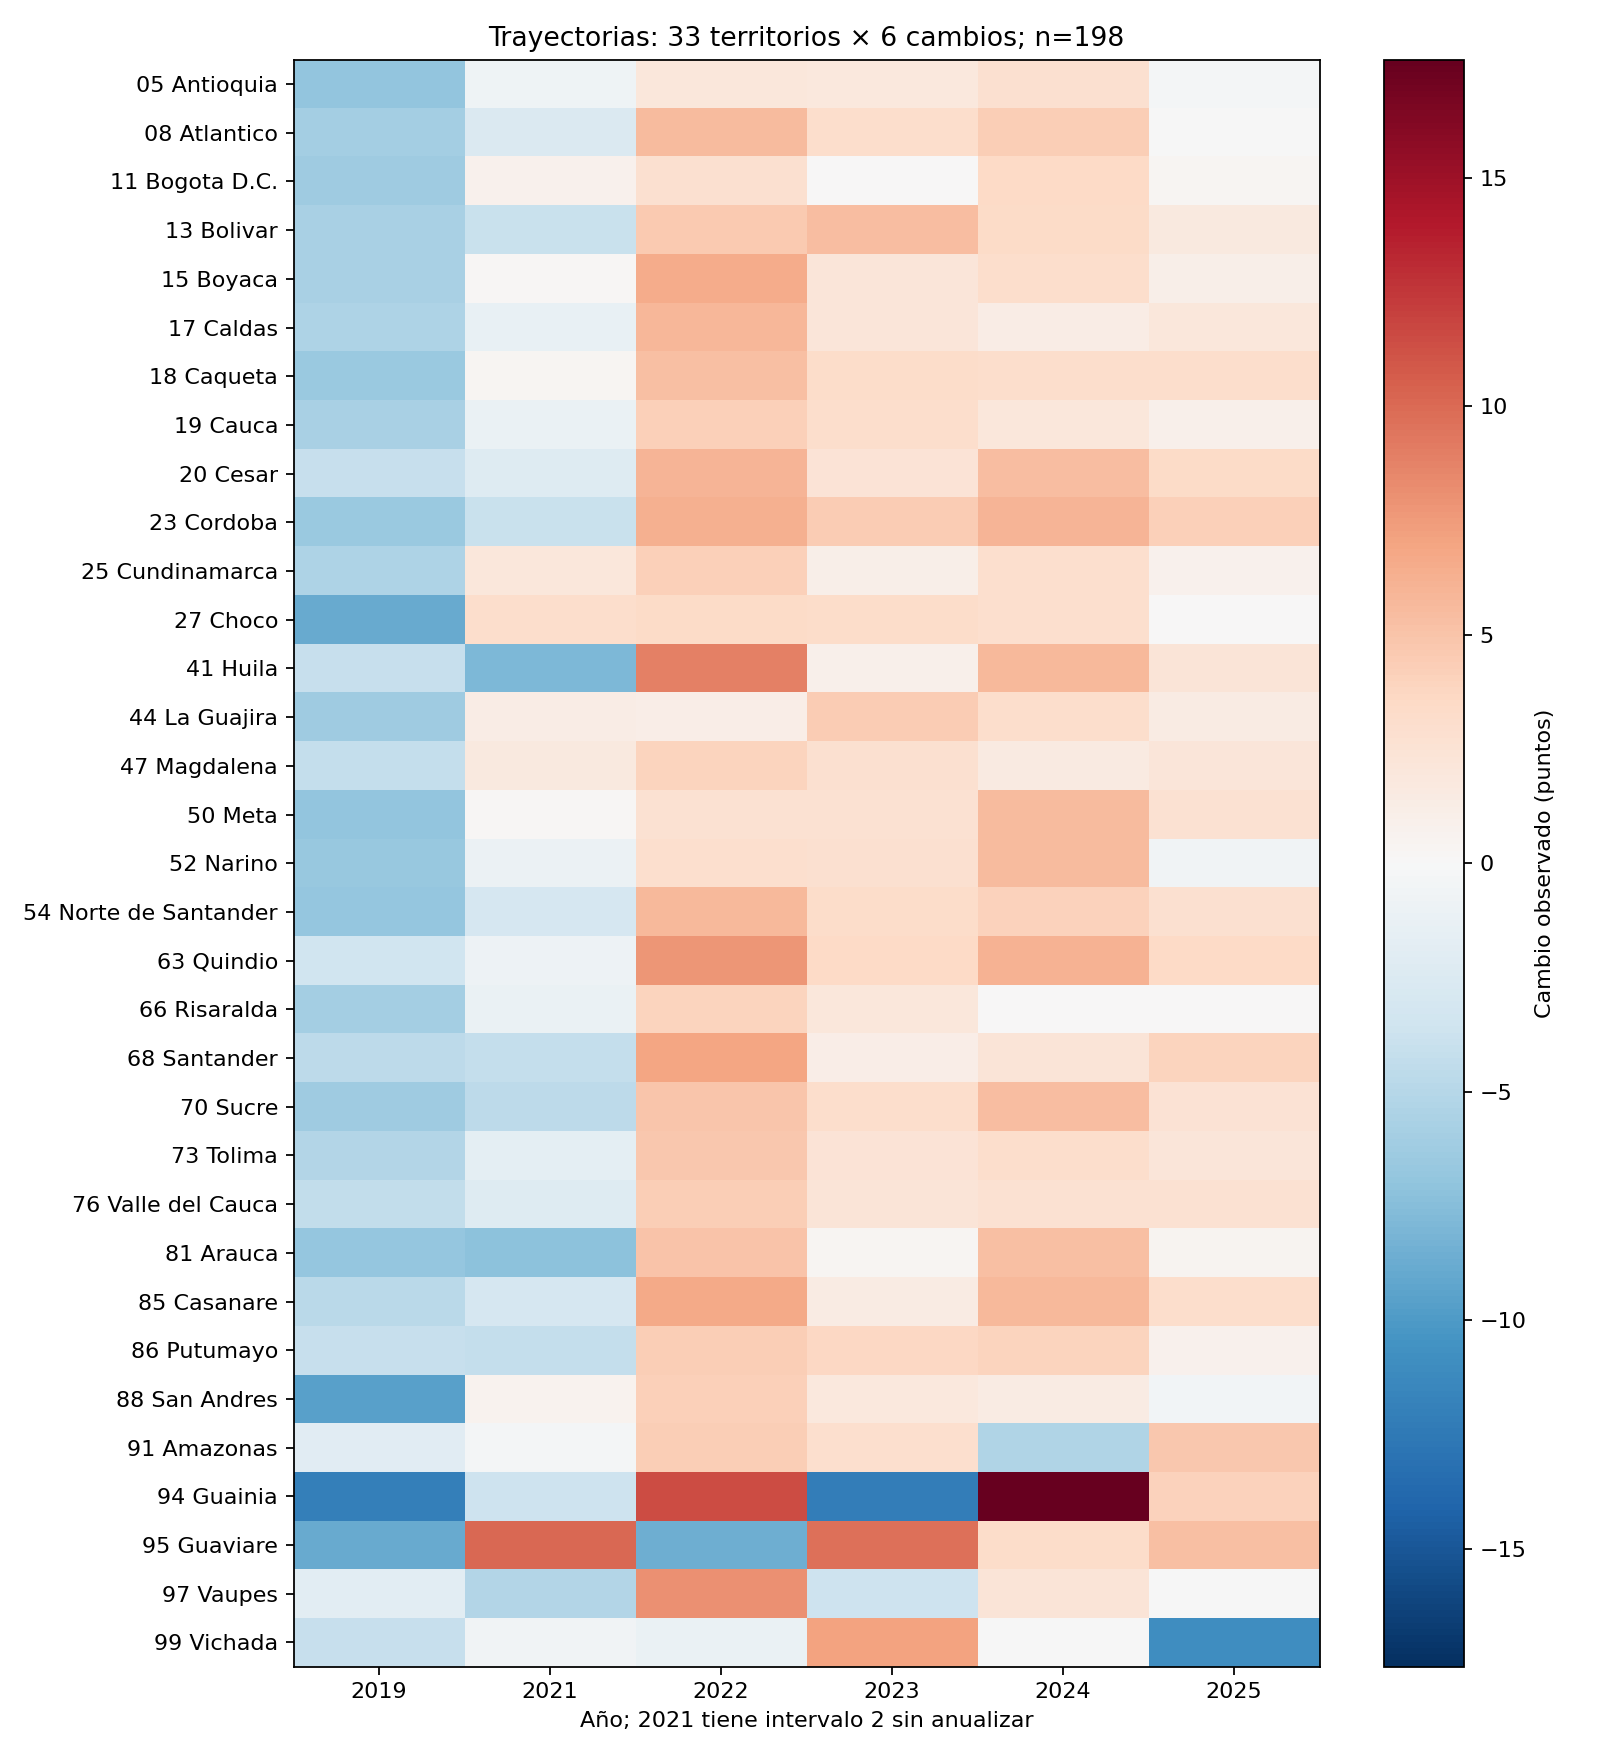

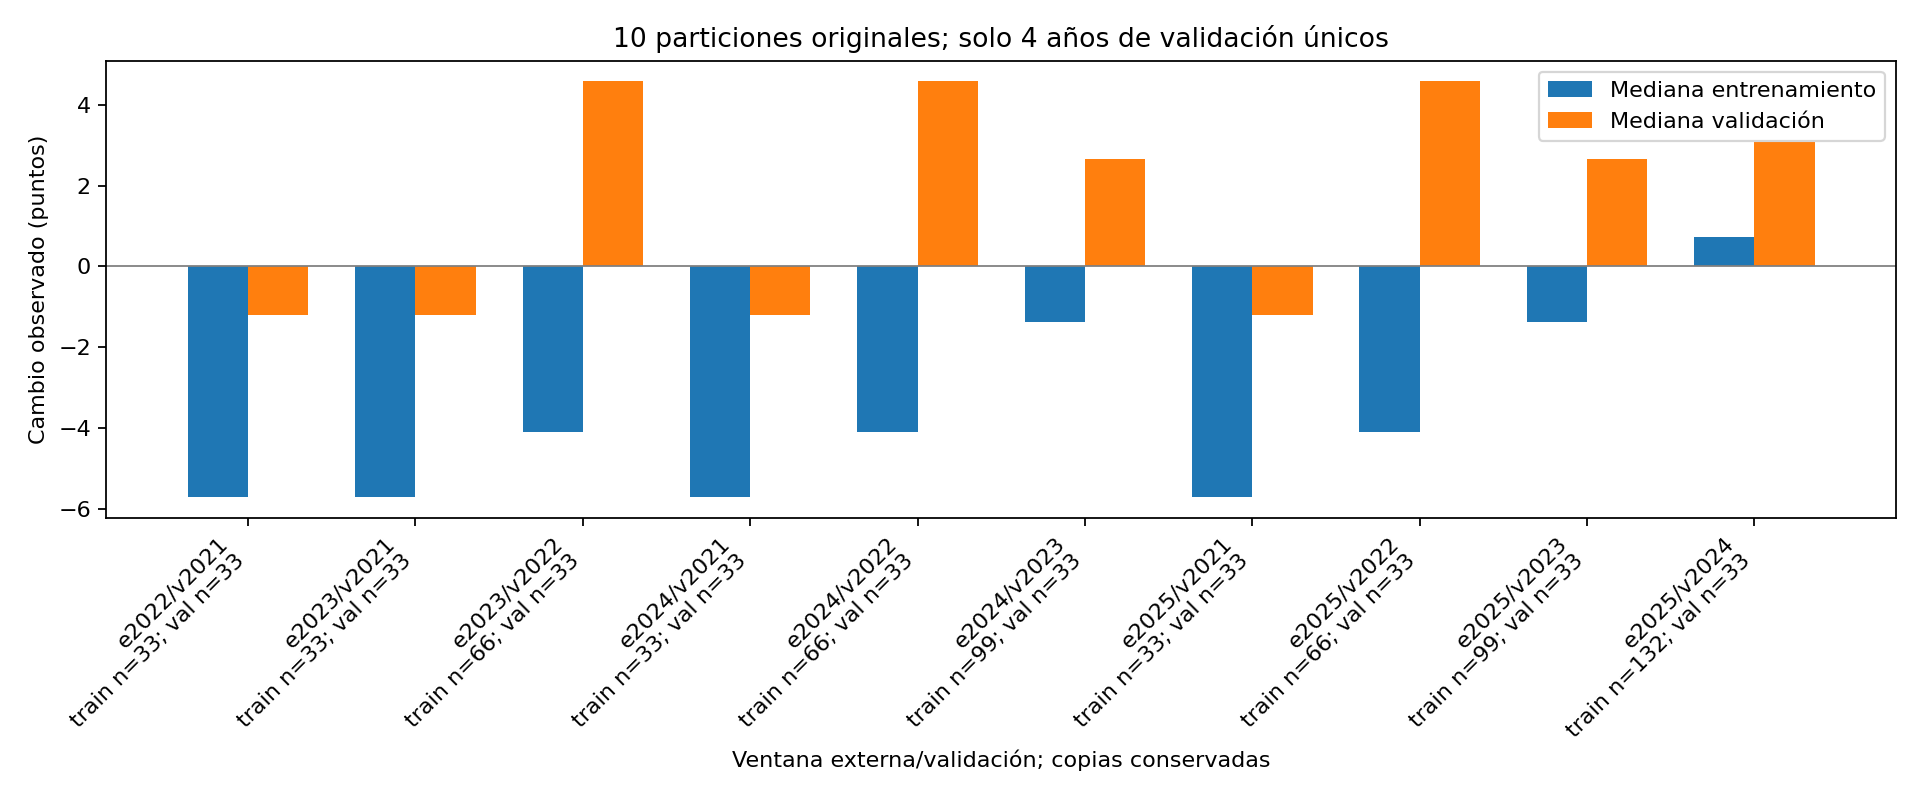

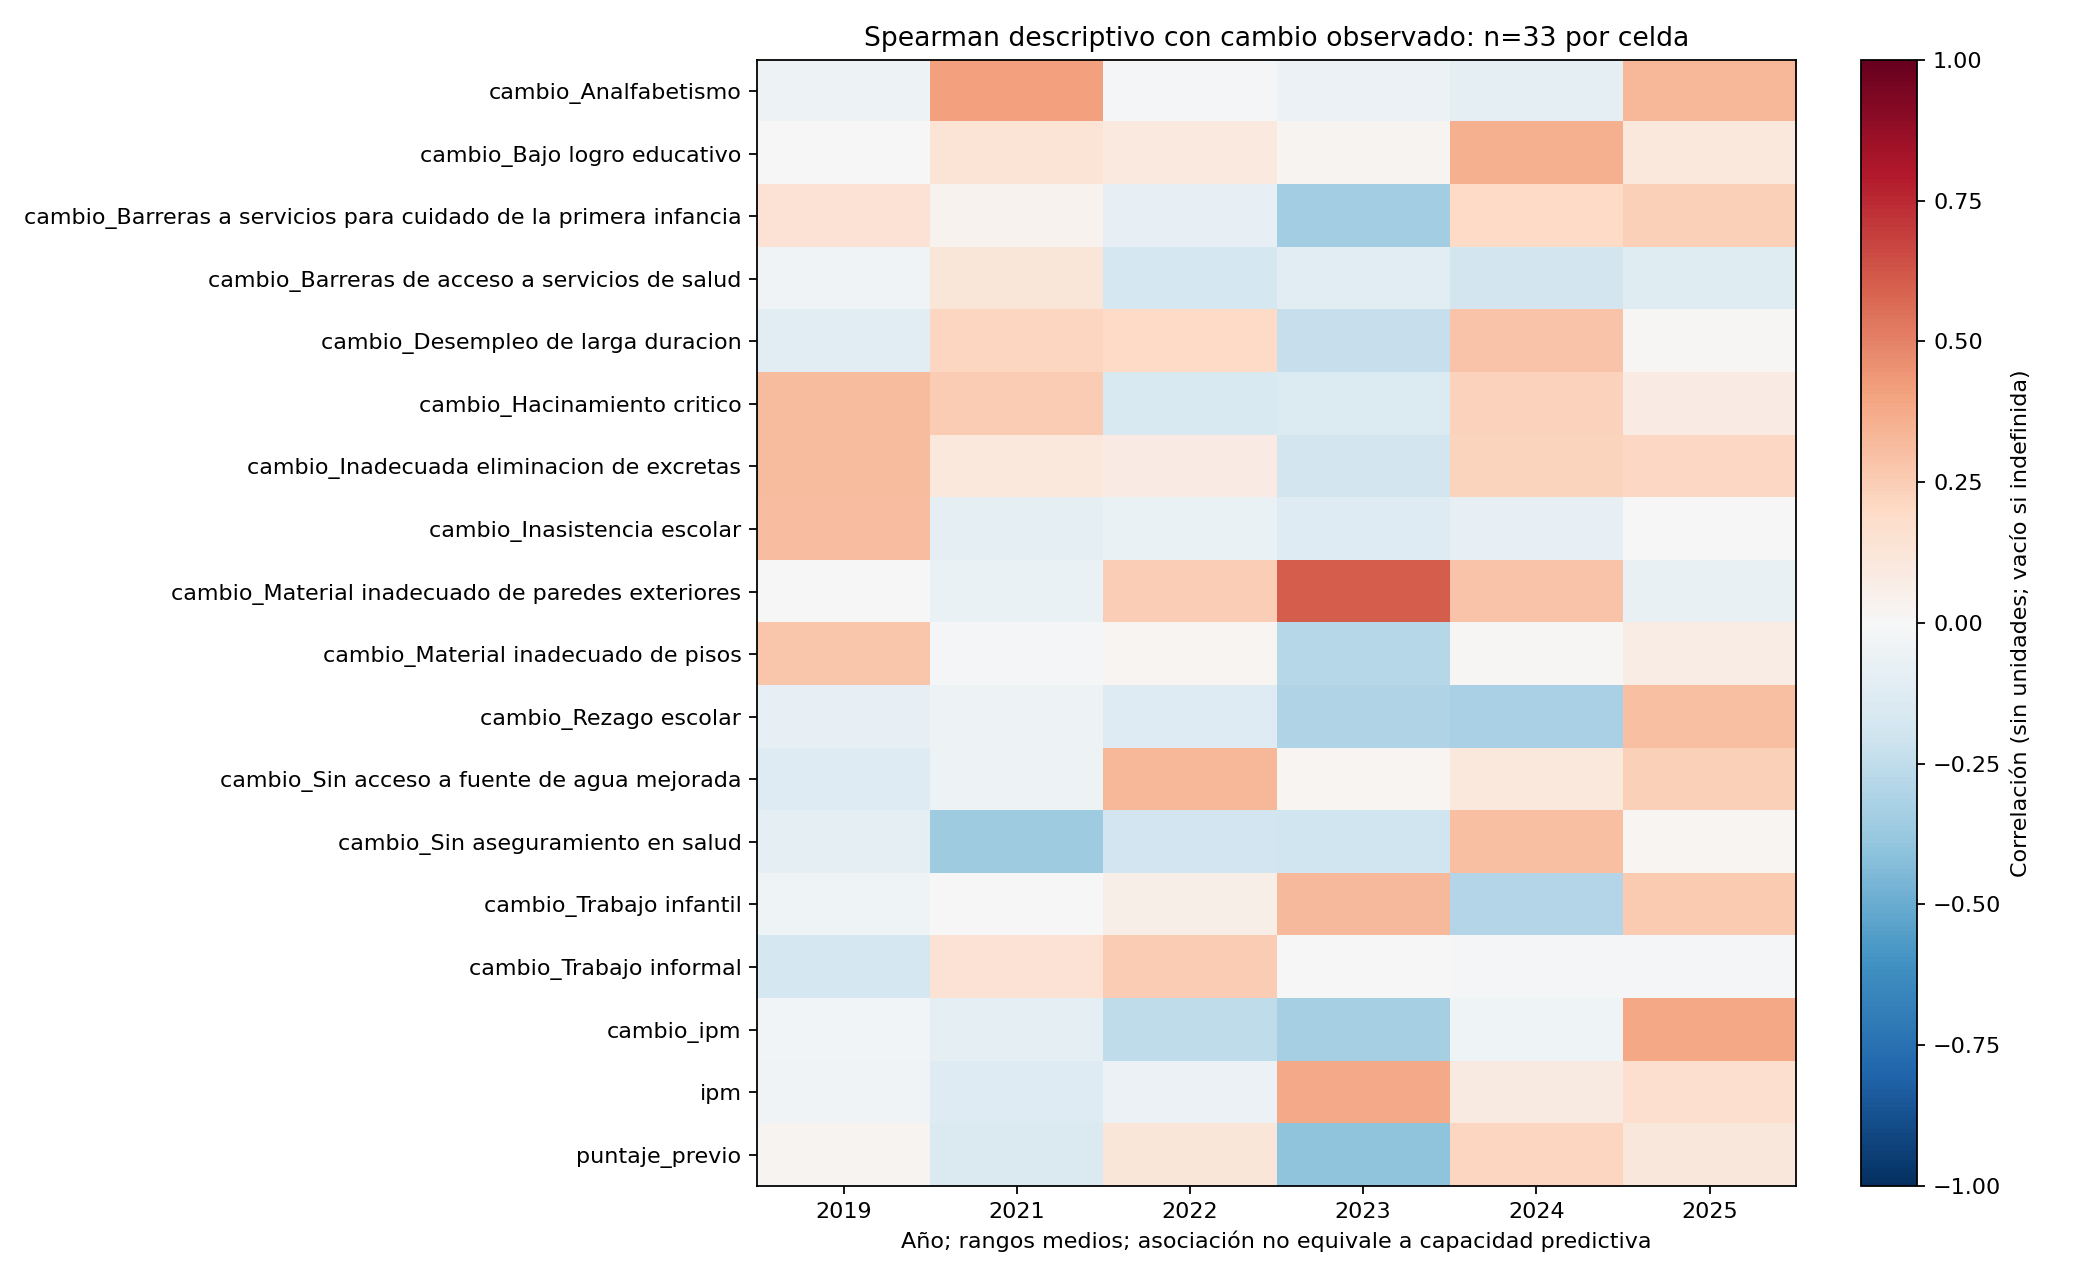

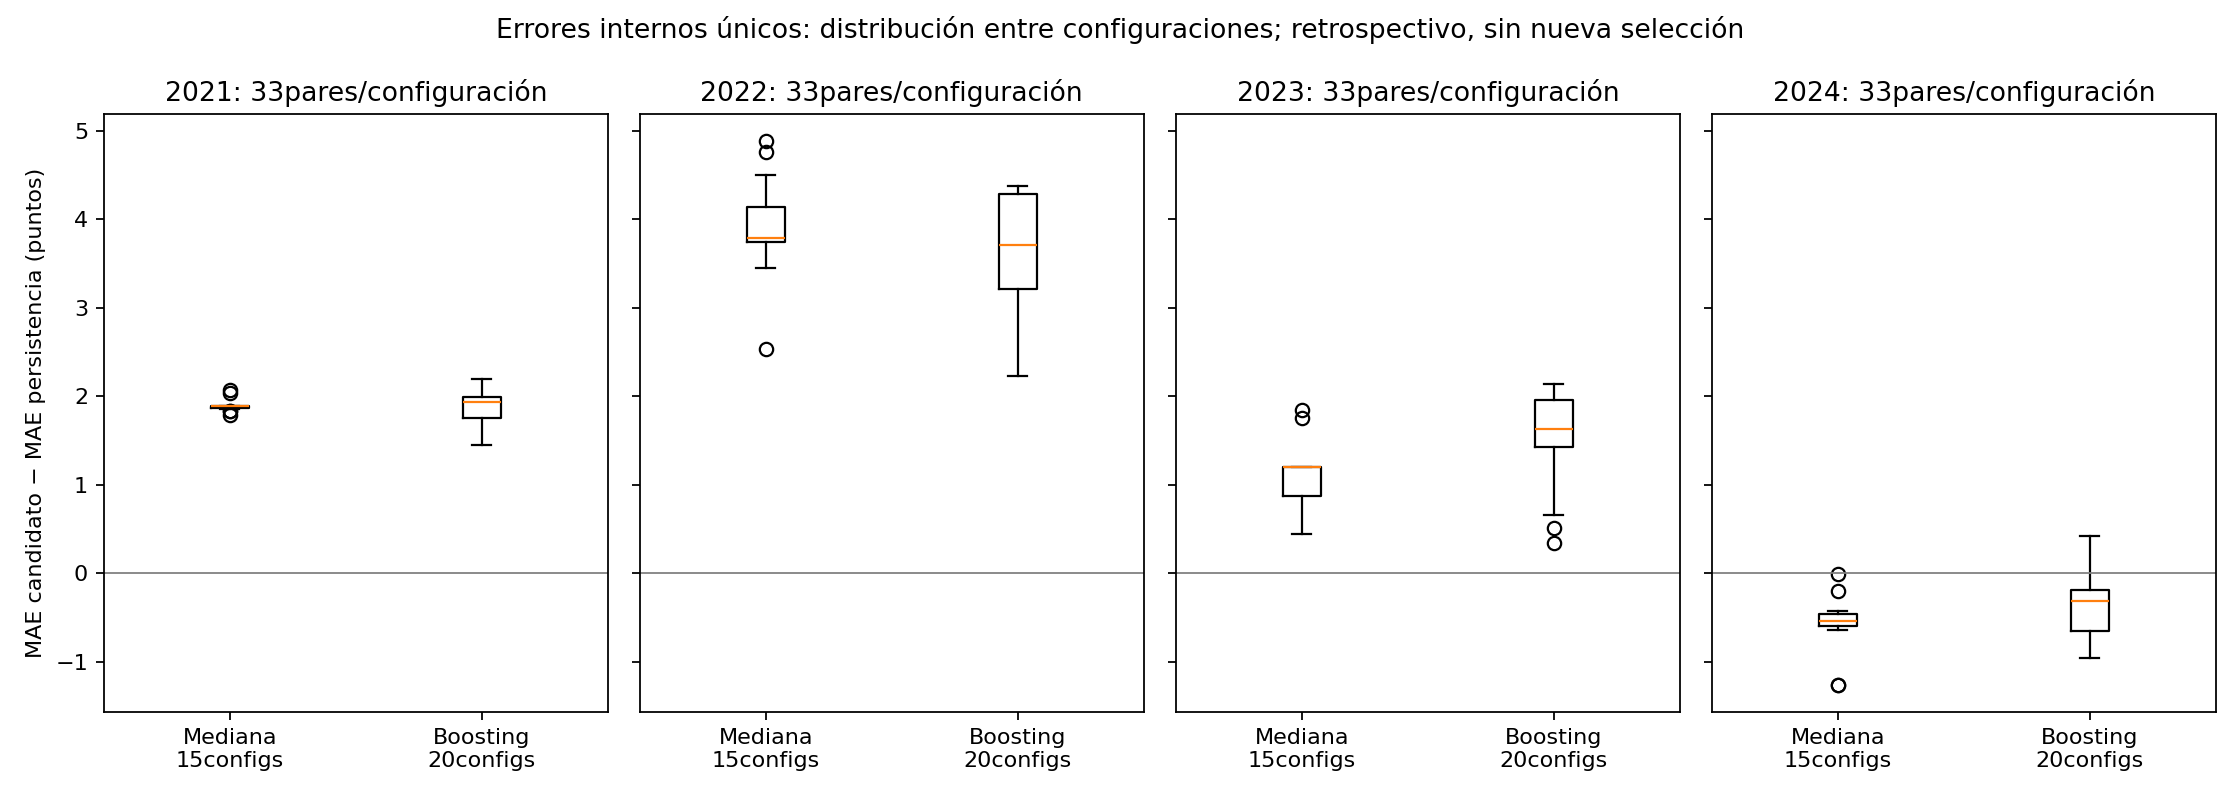

In [6]:
# En el notebook, IPython muestra las imágenes; el generador captura los PNG reales.
for name in ['01_distribuciones_anuales.png','02_trayectorias_33.png','03_contrastes_particiones.png',
             '04_asociaciones_anuales.png','05_deltas_internos.png']:
    print(name)
    if 'mostrar_png' in globals():
        mostrar_png(FIGS / name)
    else:
        from IPython.display import display, Image
        display(Image(filename=str(FIGS / name)))
